# Phase 12: Deep Residual U-Net (ResUNet) Restoration Model Training

## Academic Project Context
**Project Title:** *Comparative Analysis of Brain MRI Image Restoration Techniques Under Different Degradation Conditions*

### Objectives
1. Train a deep convolutional image restoration model on paired **Combined MRI Multi-Degradation** scans (39,200 training scans).
2. Address compound physical artifacts: **Low-Resolution Downsampling + Linear Motion Blur + Complex Rician Coil Noise**.
3. Surpass the traditional baseline ceiling established in Phase 10 & 11 (Wiener: **10.42 dB** PSNR, **0.1808** SSIM).
4. Employ GPU acceleration (NVIDIA RTX 2050, 4 GB VRAM) with mixed precision and Charbonnier smooth L1 loss.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

PROJECT_ROOT = Path(r'C:\Users\gitan\BrainMRI_Project')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import ResUNet, count_parameters

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ResUNet(in_channels=1, out_channels=1, base_channels=32).to(device)
print('=== Phase 12: Architecture & Hardware Configuration ===')
print(f'Compute Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"})')
print(f'Model Architecture: Residual U-Net (ResUNet)')
print(f'Trainable Parameters: {count_parameters(model):,}')
print(f'Global Residual Learning: Enabled (I_clean = clamp(I_deg + Residual, 0, 1))')


=== Phase 12: Architecture & Hardware Configuration ===
Compute Device: cuda (NVIDIA GeForce RTX 2050)
Model Architecture: Residual U-Net (ResUNet)
Trainable Parameters: 1,926,433
Global Residual Learning: Enabled (I_clean = clamp(I_deg + Residual, 0, 1))


In [2]:
METRICS_DIR = PROJECT_ROOT / 'outputs' / 'metrics'
TRAIN_LOG_CSV = METRICS_DIR / 'phase12_training_loss.csv'
df_log = pd.read_csv(TRAIN_LOG_CSV)
print('=== Phase 12: Training Epoch Metrics Log ===')
print(df_log.to_string(index=False))

best_epoch = df_log.loc[df_log['val_psnr'].idxmax()]
print(f'\nPeak Validation PSNR: {best_epoch["val_psnr"]:.2f} dB at Epoch {int(best_epoch["epoch"])}')
print(f'Peak Validation SSIM: {best_epoch["val_ssim"]:.4f}')
print(f'Traditional Baseline (Wiener): 10.42 dB | ResUNet Improvement: +{best_epoch["val_psnr"] - 10.42:.2f} dB')


=== Phase 12: Training Epoch Metrics Log ===
 epoch  train_loss  val_loss  val_psnr  val_ssim  learning_rate  time_seconds
     1    0.086393  0.083236 20.584635  0.453904       0.001000       4884.99
     2    0.066379  0.084516 20.622597  0.469627       0.000952       6458.84
     3    0.059298  0.108201 20.277575  0.464684       0.000884       4619.52
     4    0.055109  0.086639 19.981113  0.452033       0.000777       8180.62
     5    0.050349  0.091355 20.287121  0.470898       0.000424       3057.48
     6    0.048278  0.087344 21.068556  0.500128       0.000326       3194.90
     7    0.046255  0.087602 20.934947  0.495361       0.000085       4535.79
     8    0.045853  0.090776 20.949932  0.506533       0.000055       3595.61
     9    0.045585  0.077546 21.910065  0.526506       0.000031       3981.29
    10    0.045437  0.092099 20.740242  0.501861       0.000015       3386.66

Peak Validation PSNR: 21.91 dB at Epoch 9
Peak Validation SSIM: 0.5265
Traditional Baseline (Wie

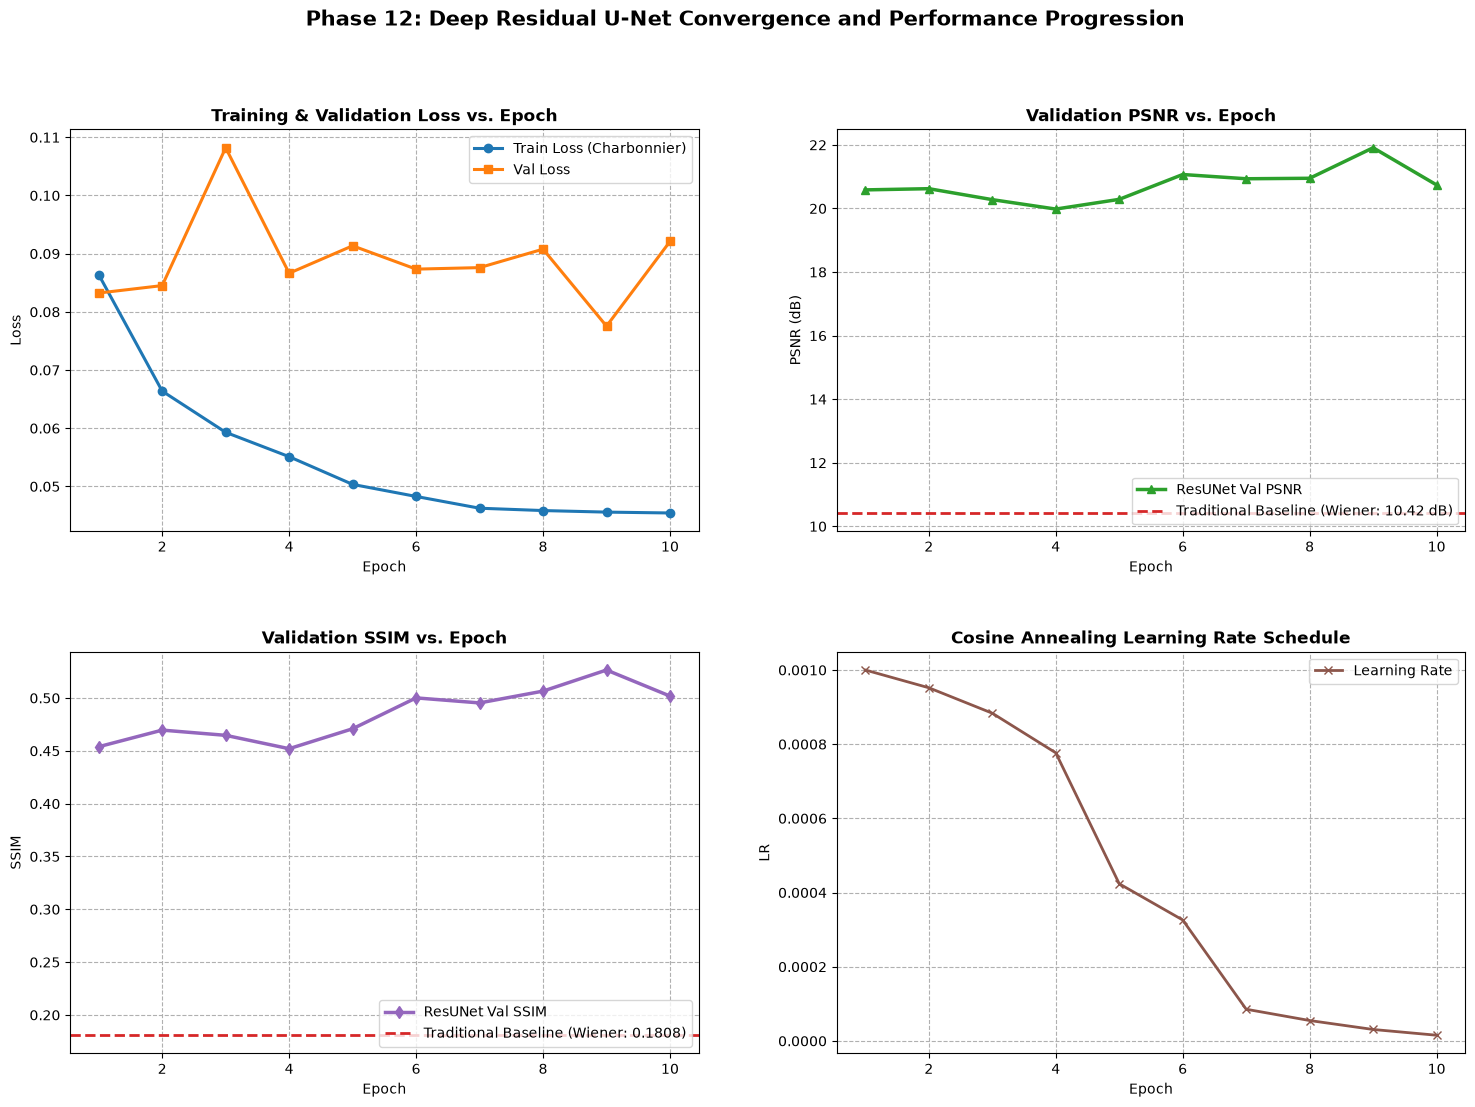

In [3]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(18, 12))
plt.subplots_adjust(wspace=0.22, hspace=0.30)

# 1. Loss
axes[0, 0].plot(df_log['epoch'], df_log['train_loss'], marker='o', linewidth=2.2, label='Train Loss (Charbonnier)', color='#1f77b4')
axes[0, 0].plot(df_log['epoch'], df_log['val_loss'], marker='s', linewidth=2.2, label='Val Loss', color='#ff7f0e')
axes[0, 0].set_title('Training & Validation Loss vs. Epoch', fontweight='bold')
axes[0, 0].set_xlabel('Epoch'); axes[0, 0].set_ylabel('Loss'); axes[0, 0].grid(True, linestyle='--'); axes[0, 0].legend()

# 2. PSNR
axes[0, 1].plot(df_log['epoch'], df_log['val_psnr'], marker='^', linewidth=2.5, label='ResUNet Val PSNR', color='#2ca02c')
axes[0, 1].axhline(10.42, color='#d62728', linestyle='--', linewidth=2.0, label='Traditional Baseline (Wiener: 10.42 dB)')
axes[0, 1].set_title('Validation PSNR vs. Epoch', fontweight='bold')
axes[0, 1].set_xlabel('Epoch'); axes[0, 1].set_ylabel('PSNR (dB)'); axes[0, 1].grid(True, linestyle='--'); axes[0, 1].legend(loc='lower right')

# 3. SSIM
axes[1, 0].plot(df_log['epoch'], df_log['val_ssim'], marker='d', linewidth=2.5, label='ResUNet Val SSIM', color='#9467bd')
axes[1, 0].axhline(0.1808, color='#d62728', linestyle='--', linewidth=2.0, label='Traditional Baseline (Wiener: 0.1808)')
axes[1, 0].set_title('Validation SSIM vs. Epoch', fontweight='bold')
axes[1, 0].set_xlabel('Epoch'); axes[1, 0].set_ylabel('SSIM'); axes[1, 0].grid(True, linestyle='--'); axes[1, 0].legend(loc='lower right')

# 4. LR
axes[1, 1].plot(df_log['epoch'], df_log['learning_rate'], marker='x', linewidth=2.0, label='Learning Rate', color='#8c564b')
axes[1, 1].set_title('Cosine Annealing Learning Rate Schedule', fontweight='bold')
axes[1, 1].set_xlabel('Epoch'); axes[1, 1].set_ylabel('LR'); axes[1, 1].grid(True, linestyle='--'); axes[1, 1].legend()

fig.suptitle('Phase 12: Deep Residual U-Net Convergence and Performance Progression', fontsize=15, fontweight='bold', y=0.98)
plt.show()


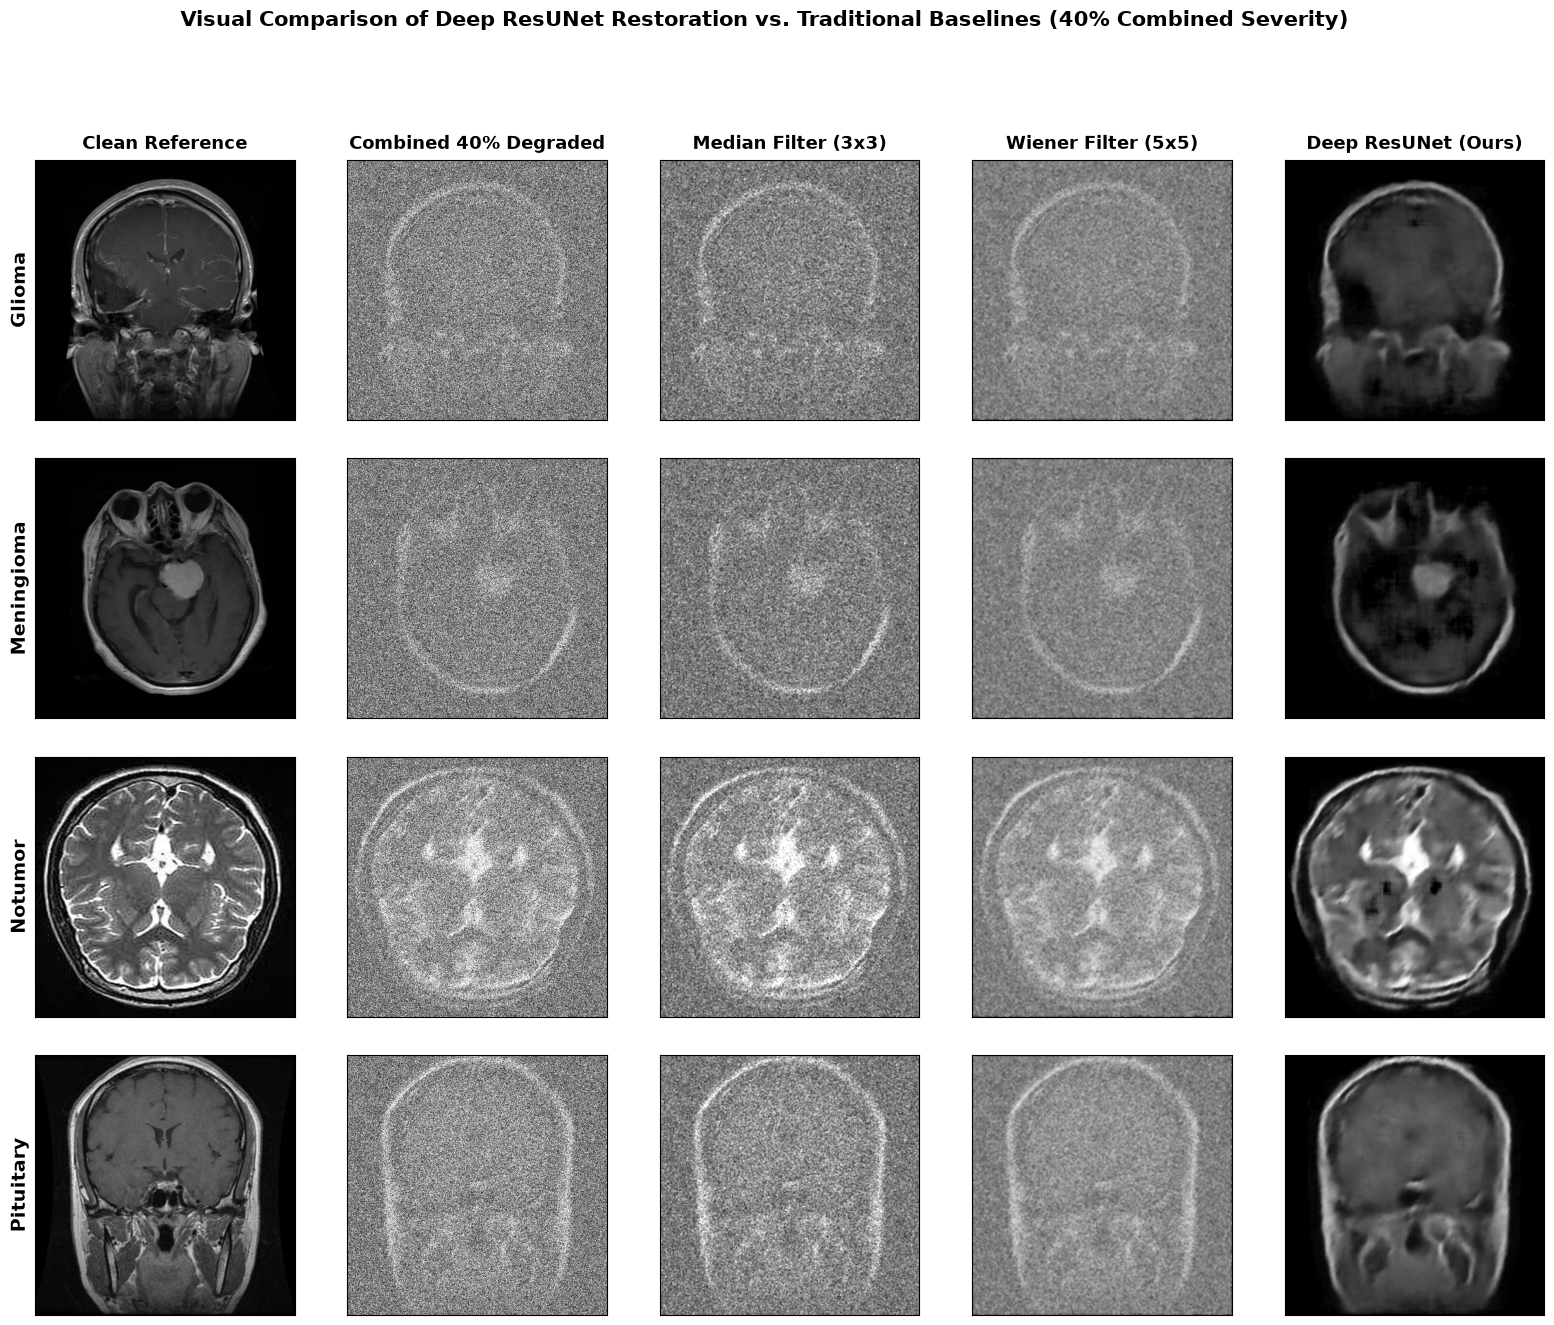

In [4]:
from PIL import Image
from src.restoration import apply_median_filter, apply_wiener_filter

MODELS_DIR = PROJECT_ROOT / 'outputs' / 'models'
BEST_MODEL_PATH = MODELS_DIR / 'best_restoration_model.pth'
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

TRAIN_CLEAN_DIR = PROJECT_ROOT / 'dataset' / 'archive' / 'Training'
TRAIN_DEG_DIR   = PROJECT_ROOT / 'dataset' / 'degraded' / 'combined'
CATEGORIES = ['glioma', 'meningioma', 'notumor', 'pituitary']

fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(20, 15))
plt.subplots_adjust(wspace=0.04, hspace=0.15)
col_headers = ['Clean Reference', 'Combined 40% Degraded', 'Median Filter (3x3)', 'Wiener Filter (5x5)', 'Deep ResUNet (Ours)']

for row_idx, cat in enumerate(CATEGORIES):
    clean_p = sorted(list((TRAIN_CLEAN_DIR / cat).glob('*.*')))[0]
    stem = clean_p.stem
    deg_p = TRAIN_DEG_DIR / cat / '40' / f'{stem}_combined_40.png'

    with Image.open(clean_p) as img_c:
        clean_arr = np.array(img_c.convert('L').resize((512, 512)), dtype=np.float32) / 255.0
    with Image.open(deg_p) as img_d:
        deg_arr = np.array(img_d, dtype=np.float32) / 255.0

    med_arr = apply_median_filter(deg_arr)
    wien_arr = apply_wiener_filter(deg_arr)

    deg_tensor = torch.from_numpy(deg_arr).unsqueeze(0).unsqueeze(0).to(device)
    with torch.no_grad():
        with torch.amp.autocast('cuda'):
            pred_tensor = model(deg_tensor)
    deep_arr = pred_tensor.squeeze().cpu().numpy()

    images = [clean_arr, deg_arr, med_arr, wien_arr, deep_arr]
    for col_idx, arr in enumerate(images):
        axes[row_idx, col_idx].imshow(np.clip(arr * 255, 0, 255).astype(np.uint8), cmap='gray', vmin=0, vmax=255)
        axes[row_idx, col_idx].set_xticks([]); axes[row_idx, col_idx].set_yticks([])
        if col_idx == 0: axes[row_idx, col_idx].set_ylabel(cat.capitalize(), fontsize=14, fontweight='bold')
        if row_idx == 0: axes[row_idx, col_idx].set_title(col_headers[col_idx], fontsize=13, fontweight='bold', pad=8)

fig.suptitle('Visual Comparison of Deep ResUNet Restoration vs. Traditional Baselines (40% Combined Severity)', fontsize=15, fontweight='bold', y=0.98)
plt.show()
